# Wildlife Re-ID

**What this notebook does.** One reproducible pipeline that builds three model versions, scores each with the *same* open-set cross-validation, explains where each gain comes from, and writes one submission file per version.

| Version | Idea | Main new ingredient |
|---|---|---|
| **V1** baseline | cosine similarity on L2-normalised MiewID descriptors, best-image-per-identity, a threshold for `new_individual` | – |
| **V2** (earlier best) | centre + PCA-whiten → k-reciprocal re-ranking → SIFT/RANSAC verification → hand-tuned blend → top-2 identity aggregation → per-species τ | local-feature geometry |
| **V3** (new) | a **learned identity ranker** (gradient boosting over per-identity evidence) + a **learned P(new_individual)** model; the two probabilities are sorted together | learning instead of hand-tuned weights; open-set decision as a probability |

**What changed and why**

* *(b) Performance gains across versions* → every version is evaluated on the same folds, plus a cumulative **ablation table** (A→F) that isolates each component.
* *(c) Error analysis* → failure taxonomy, MAP by viewpoint / identity-frequency / keypoint-count, SIFT evidence histogram, calibration of P(new), feature importance, and a limitations section.
* *Validation fix* → the CV now **simulates new individuals** (whole identities are held out), so the `new_individual` logic is tuned on a realistic open-set problem, not only on closed-set queries.

In [22]:
import os, sys, json, time, glob, hashlib, warnings, threading
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import cv2
import matplotlib
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance

warnings.filterwarnings("ignore", category=DeprecationWarning)
SEED = 0
np.random.seed(SEED)

def _env_int(name, default): return int(os.environ.get(name, default))

# ---------- data location (no personal paths: set DATA_DIR or run next to the data) ----------
def _resolve_data_dir():
    kaggle = sorted(glob.glob("/kaggle/input/*")) + sorted(glob.glob("/kaggle/input/*/*"))
    for c in [os.environ.get("DATA_DIR"), "reid_student_data_main", "."] + kaggle:
        if c and os.path.isfile(os.path.join(c, "train.csv")):
            return c
    raise FileNotFoundError("train.csv not found - set the DATA_DIR environment variable to the folder that contains it.")

DATA_DIR   = _resolve_data_dir()
PARENT_DIR = os.path.dirname(os.path.abspath(DATA_DIR))
CACHE_DIR, FIG_DIR = "cache", "figures"
OUT_DIR    = os.environ.get("OUT_DIR", ".")
for d in (CACHE_DIR, FIG_DIR, OUT_DIR): os.makedirs(d, exist_ok=True)

NEW, SPECIES = "new_individual", ["hyena", "leopard"]
SP_ID = {s: i for i, s in enumerate(SPECIES)}

# ---------- pipeline settings ----------
N_FOLDS        = _env_int("N_FOLDS", 5)
NEW_QUERY_FRAC = 0.40
OOF_QUERY_CAP  = _env_int("OOF_QUERY_CAP", 0) or None            # optional: max CV queries per (species, fold) to save SIFT time
PCA_DIM        = _env_int("PCA_DIM", 512)
RERANK_K1, RERANK_K2, RERANK_LAM = 20, 6, 0.3
CAND_K, TOP_M_SIFT = _env_int("CAND_K", 300), _env_int("TOP_M_SIFT", 150)
SIFT_RATIO, RANSAC_THRESH, RANSAC_ITERS = 0.78, 5.0, 2000
SUBMIT_VERSION = "v3"
USE_Q2Q        = os.environ.get("USE_Q2Q", "0") == "1"           # transductive cue, see section 0, note 3
assert CAND_K >= TOP_M_SIFT

# V2 hand-tuned parameters from the previous notebook (full precision file is used if present)
BEST_PARAMS = dict(w_rerank=0.2812, w_sift=0.1906, b_same=-0.0062, b_adj=0.0094, b_opp=0.0125, agg="top2", floor=3)
_cfgp = next((p for p in [os.path.join(d, "best_config_v2.json") for d in [".", DATA_DIR, PARENT_DIR]] if os.path.isfile(p)), None)
if _cfgp:
    BEST_PARAMS = json.load(open(_cfgp))["params"]; print("Loaded V2 params from", _cfgp)
assert SUBMIT_VERSION in ("v1", "v2", "v3")
print("DATA_DIR:", DATA_DIR, "| folds:", N_FOLDS, "| new-share target:", NEW_QUERY_FRAC, "| q2q:", USE_Q2Q)

def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(FIG_DIR, name), dpi=150); plt.show()

DATA_DIR: reid_student_data_main | folds: 5 | new-share target: 0.4 | q2q: False


## 1. Load data

In [23]:
def load_data(d=DATA_DIR):
    tr = pd.read_csv(f"{d}/train.csv"); te = pd.read_csv(f"{d}/test.csv")
    ids = pd.read_csv(f"{d}/miewid_ids.csv")
    col = "id" if "id" in ids.columns else ids.columns[0]
    F = np.load(f"{d}/miewid_features.npy").astype(np.float32)
    pos = pd.Series(np.arange(len(ids)), index=ids[col].to_numpy())
    Xtr, Xte = F[pos.loc[tr.id.to_numpy()].to_numpy()], F[pos.loc[te.id.to_numpy()].to_numpy()]   # KeyError if ids misalign
    for df in (tr, te): df["viewpoint"] = df["viewpoint"].fillna("unk").astype(str)
    return tr, te, Xtr, Xte

tr, te, Xtr, Xte = load_data()
print(tr.shape, te.shape, Xtr.shape, Xte.shape)
CLASSES, code_tr = np.unique(tr.identity.astype(str).to_numpy(), return_inverse=True)   # one global code per identity
code_tr = code_tr.astype(np.int32)
print(tr.groupby("species").identity.agg(["size", "nunique"]))
print("identities with a single training image:", int((tr.identity.value_counts() == 1).sum()))

(7163, 4) (2791, 3) (7163, 2152) (2791, 2152)
         size  nunique
species               
hyena    1912      205
leopard  5251      345
identities with a single training image: 102


## 2. Metric and an **open-set** cross-validation

In [24]:
NEG = -1e6
def ap5(pred, truth):
    for r, p in enumerate(pred[:5]):
        if p == truth: return 1.0 / (r + 1)
    return 0.0
def map5(preds, truths): return float(np.mean([ap5(p, t) for p, t in zip(preds, truths)]))

def make_open_set_folds(tr, k=N_FOLDS, new_frac=NEW_QUERY_FRAC, seed=SEED):
    rng = np.random.default_rng(seed)
    groups = tr.groupby("identity").indices                          # identity -> row positions
    sizes = pd.Series({i: len(r) for i, r in groups.items()})
    unseen = set(sizes.index[sizes == 1])                            # singletons can never be "known" queries
    n_unseen = len(unseen)
    for i in rng.permutation(sizes.index[sizes >= 2].to_numpy()):
        if n_unseen >= new_frac * len(tr): break
        unseen.add(i); n_unseen += sizes[i]
    fold = np.zeros(len(tr), int); is_unseen = np.zeros(len(tr), bool)
    for ident, rows in groups.items():
        if ident in unseen:
            fold[rows] = rng.integers(k); is_unseen[rows] = True     # all images of an unseen identity share a fold
        else:
            rows = rng.permutation(rows); start = rng.integers(k)
            fold[rows] = (start + np.arange(len(rows))) % k          # spread over folds -> a gallery image always remains
    return fold, is_unseen

fold_tr, unseen_tr = make_open_set_folds(tr)
print("share of train images that act as 'new' queries: %.1f%%" % (100 * unseen_tr.mean()))
print("queries per fold:", np.bincount(fold_tr, minlength=N_FOLDS))

share of train images that act as 'new' queries: 40.3%
queries per fold: [1179 1501 1477 1076 1930]


## 3. Embeddings (per species — species are never mixed)

* **RAW**: L2-normalised MiewID descriptor (used by V1).
* **PCA**: L2-norm → subtract mean → L2-norm → PCA(512, whiten) → L2-norm (used by V2/V3). Whitening equalises the variance of every component so no single dominant direction dominates the cosine.

In [25]:
def l2n(X): return X / np.maximum(np.linalg.norm(X, axis=1, keepdims=True), 1e-12)

def pca_embed(Xtr_sp, Xte_sp, dim=PCA_DIM):
    X = l2n(np.vstack([Xtr_sp, Xte_sp]).astype(np.float32))
    X = l2n(X - X.mean(0, keepdims=True))
    X = l2n(PCA(dim, whiten=True, random_state=SEED).fit_transform(X).astype(np.float32))   # unsupervised: no labels used
    return X[:len(Xtr_sp)], X[len(Xtr_sp):]

SUB, TE_SUB, EMB, RAW = {}, {}, {}, {}
for sp in SPECIES:
    m_tr, m_te = (tr.species == sp).to_numpy(), (te.species == sp).to_numpy()
    SUB[sp], TE_SUB[sp] = np.flatnonzero(m_tr), np.flatnonzero(m_te)
    EMB[sp] = pca_embed(Xtr[m_tr], Xte[m_te])
    RAW[sp] = (l2n(Xtr[m_tr]), l2n(Xte[m_te]))
    print(f"{sp}: train={m_tr.sum()} test={m_te.sum()} identities={len(np.unique(code_tr[m_tr]))}")

hyena: train=1912 test=1217 identities=205
leopard: train=5251 test=1574 identities=345


## 4. k-reciprocal re-ranking (Zhong et al., 2017)

In [26]:
def k_reciprocal_rerank(Q, G, k1=RERANK_K1, k2=RERANK_K2, lam=RERANK_LAM, chunk=1024):
    """Q (nq,d), G (ng,d): L2-normalised. Returns (S_rerank (nq,ng), S_cos (nq,ng))."""
    Q = np.ascontiguousarray(Q, dtype=np.float32); G = np.ascontiguousarray(G, dtype=np.float32)
    nq, ng = len(Q), len(G)
    X = np.vstack([Q, G]); N = nq + ng
    S_cos = Q @ G.T
    kk = min(k1, N - 1)
    D = np.empty((N, N), np.float32)                      # row-max-normalised squared euclidean distance
    nn = np.empty((N, kk + 1), np.int32)
    for a in range(0, N, chunk):
        b = min(a + chunk, N)
        d = 2.0 - 2.0 * (X[a:b] @ X.T)
        np.maximum(d, 0, out=d)
        d /= np.maximum(d.max(1, keepdims=True), 1e-12)
        D[a:b] = d
        part = np.argpartition(d, kk, axis=1)[:, :kk + 1]
        o = np.argsort(np.take_along_axis(d, part, 1), axis=1)
        nn[a:b] = np.take_along_axis(part, o, 1)
    ar = np.arange(N)
    for i in np.flatnonzero(nn[:, 0] != ar):             # exact duplicates can displace self from position 0
        w = np.flatnonzero(nn[i] == i)
        if len(w): nn[i, [0, w[0]]] = nn[i, [w[0], 0]]
        else:      nn[i] = np.r_[i, nn[i, :-1]]
    rec = (nn[nn] == ar[:, None, None]).any(2)
    h = min(int(round(k1 / 2)), kk)
    nnh = nn[:, :h + 1]
    rech = (nnh[nnh] == ar[:, None, None]).any(2)
    Rfull = [nn[i][rec[i]] for i in range(N)]
    Rhalf = [set(nnh[i][rech[i]].tolist()) for i in range(N)]
    rows, cols, vals = [], [], []
    for i in range(N):
        R = Rfull[i]; Rset = set(R.tolist()); add = set()
        for c in R.tolist():
            rc = Rhalf[c]
            if rc and sum(1 for x in rc if x in Rset) > (2.0 / 3.0) * len(rc):
                add |= rc
        idx = np.fromiter(Rset | add, dtype=np.int64)
        w = np.exp(-D[i, idx])
        rows.append(np.full(len(idx), i, np.int64)); cols.append(idx); vals.append((w / w.sum()).astype(np.float32))
    V = sparse.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(N, N))
    if k2 > 1:                                            # local query expansion
        k2e = min(k2, kk + 1)
        A = sparse.csr_matrix((np.full(N * k2e, 1.0 / k2e, np.float32), (np.repeat(ar, k2e), nn[:, :k2e].ravel())), shape=(N, N))
        V = (A @ V).tocsr()
    Vc = V.tocsc()
    rp, ri, rd = V.indptr, V.indices, V.data
    cp, ci, cd = Vc.indptr, Vc.indices, Vc.data
    J = np.empty((nq, ng), np.float32)                    # jaccard distance, queries x gallery
    for i in range(nq):
        cs, vs = ri[rp[i]:rp[i + 1]], rd[rp[i]:rp[i + 1]]
        st, en = cp[cs].astype(np.int64), cp[cs + 1].astype(np.int64)
        cnt = en - st; tot = int(cnt.sum())
        gather = np.arange(tot) + np.repeat(st - (np.cumsum(cnt) - cnt), cnt)
        tm = np.bincount(ci[gather], weights=np.minimum(cd[gather], np.repeat(vs, cnt)), minlength=N)
        J[i] = (1.0 - tm / (2.0 - tm))[nq:]
    S_rerank = 1.0 - ((1.0 - lam) * J + lam * D[:nq, nq:])
    return S_rerank.astype(np.float32), S_cos

## 5. Viewpoint compatibility
Same / adjacent / opposite / unknown viewpoint between query and gallery image (used as a small score bonus in V2 and as a feature in V3).

In [27]:
BK_SAME, BK_ADJ, BK_OPP, BK_MISSING, BK_OTHER = 0, 1, 2, 3, 4
_ADJ, _OPP = set(), set()
for a, bs in {"left": ["frontleft", "backleft"], "right": ["frontright", "backright"],
              "front": ["frontleft", "frontright"], "back": ["backleft", "backright"]}.items():
    for b in bs: _ADJ |= {(a, b), (b, a)}
for a, b in [("left", "right"), ("front", "back"), ("up", "down")]: _OPP |= {(a, b), (b, a)}

def vp_bucket(vq, vg):
    if vq == "unk" or vg == "unk": return BK_MISSING
    if vq == vg:                   return BK_SAME
    if (vq, vg) in _ADJ:           return BK_ADJ
    if (vq, vg) in _OPP:           return BK_OPP
    return BK_OTHER

VP_VOCAB = sorted(set(tr.viewpoint) | set(te.viewpoint) | {"unk"})
VP_IDX = {v: i for i, v in enumerate(VP_VOCAB)}
VP_TABLE = np.array([[vp_bucket(a, b) for b in VP_VOCAB] for a in VP_VOCAB], dtype=np.int8)
vp_id_tr = tr.viewpoint.map(VP_IDX).to_numpy().astype(np.int16)
vp_id_te = te.viewpoint.map(VP_IDX).to_numpy().astype(np.int16)
print("viewpoints:", VP_VOCAB)

viewpoints: ['back', 'backleft', 'backright', 'down', 'front', 'frontleft', 'frontright', 'left', 'right', 'unk', 'up']


## 6. SIFT + RANSAC pair verification (with a **pair-level cache**)

In [28]:
# ---------- SIFT source (.npz, or an unzipped folder of <id>_xy.npy / <id>_desc.npy) ----------
def locate_sift(name):
    roots = [os.environ.get("SIFT_DIR"), DATA_DIR, PARENT_DIR, os.getcwd()] + sorted(glob.glob("/kaggle/input/*")) + sorted(glob.glob("/kaggle/input/*/*"))
    for r in roots:
        if not r: continue
        for nm in (name, name[:-4] if name.endswith(".npz") else name):
            p = os.path.join(r, nm)
            if os.path.exists(p): return p
    raise FileNotFoundError(f"{name} not found in {roots} - set SIFT_DIR to the folder that contains it.")

class SiftSource:
    def __init__(self, path):
        self.zs, self.dir, self.map = [], None, None
        if os.path.isfile(path): self.zs = [np.load(path)]
        else:
            npzs = sorted(glob.glob(os.path.join(path, "**", "*.npz"), recursive=True))
            if npzs: self.zs = [np.load(p) for p in npzs]
            else:    self.dir = path
        print("SIFT source:", path, "| mode:", "npz" if self.zs else "folder of .npy")
    def get(self, key):
        for z in self.zs:
            try: return z[key]
            except KeyError: continue
        if self.dir is not None:
            p = os.path.join(self.dir, key + ".npy")
            if os.path.exists(p): return np.load(p)
            if self.map is None:
                self.map = {os.path.splitext(os.path.basename(q))[0]: q for q in glob.glob(os.path.join(self.dir, "**", "*.npy"), recursive=True)}
            return np.load(self.map[key])
        raise KeyError(key)

_TR_IDS, _TE_IDS = set(tr.id.to_numpy()), set(te.id.to_numpy())
def load_sift_for(ids_needed):
    srcs = [(SiftSource(locate_sift("sift_features_train.npz")), _TR_IDS), (SiftSource(locate_sift("sift_features_test.npz")), _TE_IDS)]
    out, t0 = {}, time.time()
    for n, i in enumerate(ids_needed):
        for src, idset in srcs:
            if i in idset:
                out[i] = (src.get(f"{i}_xy").reshape(-1, 2).astype(np.float32), src.get(f"{i}_desc").reshape(-1, 128)); break
        if (n + 1) % 2000 == 0: print(f"  loaded {n+1}/{len(ids_needed)} SIFT arrays [{time.time()-t0:.0f}s]")
    print(f"SIFT loaded: {len(out)} images [{time.time()-t0:.0f}s]")
    return out

_tls = threading.local()
def _bf():
    if not hasattr(_tls, "bf"): _tls.bf = cv2.BFMatcher(cv2.NORM_L2)
    return _tls.bf

def _pair_stats(bf, xq, dq32, xg, dg):
    """(ratio_matches, ransac_inliers) for one image pair."""
    if len(xq) < 4 or len(xg) < 4: return 0, 0
    dg32 = dg.astype(np.float32)
    knn = bf.knnMatch(dq32, dg32, k=2)
    good = [m[0] for m in knn if len(m) == 2 and m[0].distance < SIFT_RATIO * m[1].distance]      # Lowe ratio test
    if not good: return 0, 0
    rev = bf.match(dg32, dq32)                                                                      # mutual NN check
    rt = np.fromiter((r.trainIdx for r in rev), dtype=np.int64, count=len(rev))
    good = [m for m in good if rt[m.trainIdx] == m.queryIdx]
    if len(good) < 4: return len(good), 0
    pq = np.float32([xq[m.queryIdx] for m in good]); pg = np.float32([xg[m.trainIdx] for m in good])
    cv2.setRNGSeed(0)
    _, mask = cv2.estimateAffinePartial2D(pq, pg, method=cv2.RANSAC, ransacReprojThreshold=RANSAC_THRESH, maxIters=RANSAC_ITERS)
    return len(good), (0 if mask is None else int(mask.sum()))

def run_sift(SIFT, q_list, g_lists, label, chunk=20):
    """q_list[i] is matched against every id in g_lists[i]. Returns int32 (total_pairs, 4): n_kp_q, n_kp_g, ratio_matches, ransac_inliers."""
    cv2.setNumThreads(1)
    def work(items):
        bf, out = _bf(), []
        for qid, gids in items:
            xq, dq = SIFT[qid]; dq32 = dq.astype(np.float32)
            for gid in gids:
                xg, dg = SIFT[gid]
                nm, ni = _pair_stats(bf, xq, dq32, xg, dg)
                out.append((len(xq), len(xg), nm, ni))
        return np.array(out, dtype=np.int32).reshape(-1, 4)
    tasks = [list(zip(q_list[a:a + chunk], g_lists[a:a + chunk])) for a in range(0, len(q_list), chunk)]
    workers = max(1, os.cpu_count() or 1)
    print(f"[{label}] {sum(len(g) for g in g_lists):,} pairs on {workers} thread(s)")
    t0, res = time.time(), []
    with ThreadPoolExecutor(max_workers=workers) as ex:
        for n, r in enumerate(ex.map(work, tasks)):
            res.append(r)
            if (n + 1) % max(1, len(tasks) // 10) == 0: print(f"  {n+1}/{len(tasks)} chunks [{time.time()-t0:.0f}s]")
    return np.concatenate(res)

# ---------- pair cache: int64 key = query_index * N + gallery_index over the concatenated [train, test] id list ----------
ALL_IDS = np.concatenate([tr.id.to_numpy(dtype=object), te.id.to_numpy(dtype=object)]); NID = len(ALL_IDS)
_IDX = pd.Index(ALL_IDS); assert _IDX.is_unique, "image ids must be unique across train and test"
def pair_key(q, g):
    qi, gi = _IDX.get_indexer(q), _IDX.get_indexer(g)
    assert (qi >= 0).all() and (gi >= 0).all(), "unknown image id"
    return qi.astype(np.int64) * NID + gi

class PairCache:
    def __init__(self, path):
        self.path = path
        self.sig = dict(ratio=SIFT_RATIO, ransac=RANSAC_THRESH, iters=RANSAC_ITERS, ids=hashlib.md5("|".join(ALL_IDS).encode()).hexdigest()[:12])
        self.keys, self.stats = np.empty(0, np.int64), np.empty((0, 4), np.int32)
        src = path if os.path.exists(path) else next(iter(sorted(glob.glob("/kaggle/input/*/sift_pair_cache.npz") + glob.glob("/kaggle/input/*/*/sift_pair_cache.npz"))), None)
        if src:
            z = np.load(src)
            if json.loads(str(z["sig"])) == self.sig: self.keys, self.stats = z["keys"], z["stats"]; print(f"pair cache: {len(self.keys):,} pairs loaded")
            else: print("pair cache signature differs (params or ids changed) -> ignored")
    def lookup(self, keys):
        if len(self.keys) == 0: return np.full(len(keys), -1, np.int64)
        i = np.minimum(np.searchsorted(self.keys, keys), len(self.keys) - 1)
        return np.where(self.keys[i] == keys, i, -1)
    def add(self, keys, stats):
        allk = np.concatenate([self.keys, keys]); alls = np.concatenate([self.stats, stats.astype(np.int32)])
        u, first = np.unique(allk, return_index=True)
        self.keys, self.stats = u, alls[first]
    def save(self):
        np.savez_compressed(self.path, keys=self.keys, stats=self.stats, sig=np.array(json.dumps(self.sig)))

PAIRS = PairCache(os.path.join(CACHE_DIR, "sift_pair_cache.npz"))

def seed_from_legacy():
    """Import pairs from the old notebook's cache/sift_<kind>_top*.parquet|csv.gz if its SIFT parameters match ours."""
    mp = os.path.join(CACHE_DIR, "sift_meta.json")
    if not os.path.exists(mp): return
    meta, added = json.load(open(mp)), 0
    for kind, s in meta.items():
        if not (isinstance(s, dict) and s.get("ratio") == SIFT_RATIO and s.get("ransac") == RANSAC_THRESH and s.get("iters") == RANSAC_ITERS): continue
        for p in sorted(glob.glob(os.path.join(CACHE_DIR, f"sift_{kind}_top*.parquet")) + glob.glob(os.path.join(CACHE_DIR, f"sift_{kind}_top*.csv.gz"))):
            try: df = pd.read_parquet(p) if p.endswith(".parquet") else pd.read_csv(p)
            except Exception as e: print("  could not read", p, type(e).__name__); continue
            qi, gi = _IDX.get_indexer(df.query_id.to_numpy(dtype=object)), _IDX.get_indexer(df.gallery_id.to_numpy(dtype=object)); ok = (qi >= 0) & (gi >= 0)
            PAIRS.add(qi[ok].astype(np.int64) * NID + gi[ok], df[["n_kp_q", "n_kp_g", "ratio_matches", "ransac_inliers"]].to_numpy(np.int32)[ok]); added += int(ok.sum()); break
    if added: print(f"imported {added:,} pairs from the legacy cache"); PAIRS.save()
seed_from_legacy()

def sift_stats(qids, gid_mat, label):
    """qids (nq,), gid_mat (nq, M) -> int32 (nq*M, 4). Only pairs missing from the cache are computed."""
    nq, M = gid_mat.shape
    q_rep, g_flat = np.repeat(np.asarray(qids, dtype=object), M), gid_mat.ravel()
    keys = pair_key(q_rep, g_flat); pos = PAIRS.lookup(keys); miss = np.flatnonzero(pos < 0)
    print(f"[{label}] pairs: {len(keys):,} | cached: {len(keys) - len(miss):,} | to compute: {len(miss):,}")
    if len(miss):
        grp = pd.DataFrame({"q": q_rep[miss], "g": g_flat[miss]}).groupby("q", sort=False)["g"].agg(list)
        q_list, g_lists = list(grp.index), list(grp.values)
        SIFT = load_sift_for(list(dict.fromkeys(q_list + [g for gl in g_lists for g in gl])))
        st = run_sift(SIFT, q_list, g_lists, label)
        PAIRS.add(pair_key(np.repeat(np.array(q_list, dtype=object), [len(l) for l in g_lists]), np.array([g for gl in g_lists for g in gl], dtype=object)), st)
        PAIRS.save(); pos = PAIRS.lookup(keys); assert (pos >= 0).all()
    return PAIRS.stats[pos]

pair cache: 995,400 pairs loaded


## 7. Candidate pools (one generic builder for CV folds **and** the test set)

In [29]:
def topk_sorted(S, K):
    part = np.argpartition(-S, K - 1, axis=1)[:, :K]
    return np.take_along_axis(part, np.argsort(-np.take_along_axis(S, part, 1), axis=1), 1)

def build_pool(sp, q_pos, q_ids, vq, Pq, Rq, g_rows, Pg, Rg):
    """q_pos: row positions of the queries in their own frame; g_rows: gallery row positions in `tr`."""
    K = CAND_K; assert len(g_rows) >= K, f"gallery has {len(g_rows)} images; lower CAND_K"
    Sr, Sc = k_reciprocal_rerank(Pq, Pg)
    cand = topk_sorted(Sr, K)
    gcode = code_tr[g_rows]; gcnt = np.bincount(gcode, minlength=len(CLASSES)); vg = vp_id_tr[g_rows]
    Rs = Rq @ Rg.T; rc = topk_sorted(Rs, K)                       # V1: plain cosine on RAW descriptors
    qq = Pq @ Pq.T; np.fill_diagonal(qq, -1.0)                    # query-to-query similarity (optional transductive cue)
    gc = gcode[cand].astype(np.int32)
    return dict(Sr=np.take_along_axis(Sr, cand, 1), Sc=np.take_along_axis(Sc, cand, 1),
                bk=VP_TABLE[vq[:, None], vg[cand]], gc=gc, gn=gcnt[gc].astype(np.float32), cand=g_rows[cand].astype(np.int32),
                q_rows=np.asarray(q_pos), qid=np.asarray(q_ids, dtype=object), sp=np.full(len(q_pos), SP_ID[sp], np.int8), q_vp=vq,
                q2q1=qq.max(1), q2q3=np.sort(qq, axis=1)[:, -3:].mean(1),
                r_sc=np.take_along_axis(Rs, rc, 1), r_gc=gcode[rc].astype(np.int32))

def concat_pools(parts): return {k: np.concatenate([p[k] for p in parts]) for k in parts[0]}

# ---------- cross-validation pools ----------
t0, parts, rng_cap = time.time(), [], np.random.default_rng(SEED + 1)
tr_ids = tr.id.to_numpy(dtype=object)
for sp in SPECIES:
    rows = SUB[sp]; P_tr, _ = EMB[sp]; R_tr, _ = RAW[sp]; f = fold_tr[rows]
    for k in range(N_FOLDS):
        q_loc, g_loc = np.flatnonzero(f == k), np.flatnonzero(f != k)
        if OOF_QUERY_CAP and len(q_loc) > OOF_QUERY_CAP: q_loc = np.sort(rng_cap.choice(q_loc, OOF_QUERY_CAP, replace=False))
        pool = build_pool(sp, rows[q_loc], tr_ids[rows[q_loc]], vp_id_tr[rows[q_loc]], P_tr[q_loc], R_tr[q_loc], rows[g_loc], P_tr[g_loc], R_tr[g_loc])
        pool["fold"] = np.full(len(q_loc), k, np.int8); parts.append(pool)
        print(f"  CV {sp} fold {k}: queries={len(q_loc)} gallery={len(g_loc)} [{time.time()-t0:.0f}s]")
P_OOF = concat_pools(parts)
tcode_oof = np.where(unseen_tr[P_OOF["q_rows"]], -1, code_tr[P_OOF["q_rows"]])      # -1 = truth is new_individual
print("CV queries:", len(tcode_oof), "| new share: %.1f%%" % (100 * (tcode_oof < 0).mean()))

# ---------- test pool (gallery = full train) ----------
te_ids = te.id.to_numpy(dtype=object); parts = []
for sp in SPECIES:
    P_tr, P_te = EMB[sp]; R_tr, R_te = RAW[sp]; qr = TE_SUB[sp]
    parts.append(build_pool(sp, qr, te_ids[qr], vp_id_te[qr], P_te, R_te, SUB[sp], P_tr, R_tr))
    print(f"  TEST {sp}: queries={len(qr)} gallery={len(SUB[sp])}")
P_TE = concat_pools(parts)
print("queries per CV fold vs test:", len(tcode_oof) // N_FOLDS, "vs", len(te), "(relevant for USE_Q2Q)")

  CV hyena fold 0: queries=403 gallery=1509 [0s]
  CV hyena fold 1: queries=377 gallery=1535 [0s]
  CV hyena fold 2: queries=387 gallery=1525 [1s]
  CV hyena fold 3: queries=359 gallery=1553 [1s]
  CV hyena fold 4: queries=386 gallery=1526 [1s]
  CV leopard fold 0: queries=776 gallery=4475 [3s]
  CV leopard fold 1: queries=1124 gallery=4127 [4s]
  CV leopard fold 2: queries=1090 gallery=4161 [5s]
  CV leopard fold 3: queries=717 gallery=4534 [6s]
  CV leopard fold 4: queries=1544 gallery=3707 [8s]
CV queries: 7163 | new share: 40.3%
  TEST hyena: queries=1217 gallery=1912
  TEST leopard: queries=1574 gallery=5251
queries per CV fold vs test: 1432 vs 2791 (relevant for USE_Q2Q)


### 7b. Attach SIFT/RANSAC statistics to the top-`TOP_M_SIFT` candidates
Candidates beyond rank `TOP_M_SIFT` get zeros (as in V2). **This is the slow step on a first run**; later runs read the pair cache.

In [30]:
def attach_sift(P, label):
    nq, K = P["Sr"].shape; M = min(TOP_M_SIFT, K)
    st = sift_stats(P["qid"], tr_ids[P["cand"][:, :M]], label).reshape(nq, M, 4)
    for j, name in enumerate(["kq", "kg", "nm", "inl"]):
        a = np.zeros((nq, K), np.float32); a[:, :M] = st[:, :, j]; P[name] = a

attach_sift(P_TE, "test")
attach_sift(P_OOF, "cv")
same = (P_OOF["gc"][:, :TOP_M_SIFT] == tcode_oof[:, None])
print("share of top-M pairs with 0 inliers: %.1f%%" % (100 * (P_OOF["inl"][:, :TOP_M_SIFT] == 0).mean()))
print("mean inliers  same-identity: %.1f | different-identity: %.1f" % (P_OOF["inl"][:, :TOP_M_SIFT][same].mean(), P_OOF["inl"][:, :TOP_M_SIFT][~same].mean()))

[test] pairs: 418,650 | cached: 279,100 | to compute: 139,550
SIFT source: c:\Users\anupd\Documents\wildlife-reid\sift_features_train.npz | mode: folder of .npy
SIFT source: c:\Users\anupd\Documents\wildlife-reid\sift_features_test.npz | mode: folder of .npy
  loaded 2000/9922 SIFT arrays [1s]
  loaded 4000/9922 SIFT arrays [2s]
  loaded 6000/9922 SIFT arrays [4s]
  loaded 8000/9922 SIFT arrays [5s]
SIFT loaded: 9922 images [6s]
[test] 139,550 pairs on 22 thread(s)
  14/140 chunks [25s]
  28/140 chunks [25s]
  42/140 chunks [36s]
  56/140 chunks [40s]
  70/140 chunks [52s]
  84/140 chunks [76s]
  98/140 chunks [84s]
  112/140 chunks [89s]
  126/140 chunks [91s]
  140/140 chunks [95s]
[cv] pairs: 1,074,450 | cached: 716,300 | to compute: 358,150
SIFT source: c:\Users\anupd\Documents\wildlife-reid\sift_features_train.npz | mode: folder of .npy
SIFT source: c:\Users\anupd\Documents\wildlife-reid\sift_features_test.npz | mode: folder of .npy
  loaded 2000/7163 SIFT arrays [1s]
  loaded 400

## 8. Scoring helpers: blend, identity aggregation, `new_individual` insertion

* `blend` = V2's hand-tuned image score `w·S_rerank + (1−w)·S_cos + w_sift·log(1+max(inliers−floor,0)) + viewpoint bonus`.
* `agg_topk` turns image scores into identity scores (`max` or mean of the best-`k` images of that identity).
* `new_individual` is inserted at position = number of identities whose score ≥ τ (capped at 4). In V3, τ is replaced by the model's own `P(new)` and the scores are probabilities, so the comparison is "is the new-individual hypothesis more probable than this identity?".
* `tune_tau` picks τ per species to maximise CV MAP@5 (one number per species, so over-fitting is negligible).

In [31]:
def agg_topk(sc, gc, agg="max", topn=5):
    nq, K = sc.shape
    k = 1 if agg == "max" else int(agg[3:])
    o1 = np.argsort(-sc, axis=1)
    gc1 = np.take_along_axis(gc, o1, 1)
    o2 = np.argsort(gc1, axis=1, kind="stable")
    order = np.take_along_axis(o1, o2, 1)
    A, V = np.take_along_axis(gc, order, 1), np.take_along_axis(sc, order, 1)
    acc, cnt = V.astype(np.float32).copy(), np.ones((nq, K), np.float32)
    for j in range(1, k):
        same = A[:, j:] == A[:, :K - j]
        acc[:, :K - j] += np.where(same, V[:, j:], 0); cnt[:, :K - j] += same
    first = np.ones((nq, K), bool); first[:, 1:] = A[:, 1:] != A[:, :-1]
    gs = np.where(first, acc / cnt, NEG).astype(np.float32)
    kk = min(topn, K)
    part = np.argpartition(-gs, kk - 1, axis=1)[:, :kk]
    sel = np.take_along_axis(part, np.argsort(-np.take_along_axis(gs, part, 1), axis=1), 1)
    ids, scs = np.take_along_axis(A, sel, 1), np.take_along_axis(gs, sel, 1)
    return np.where(scs > NEG / 2, ids, -2).astype(np.int32), scs

def blend(P, p):
    btab = np.array([p["b_same"], p["b_adj"], p["b_opp"], 0.0, 0.0], np.float32)   # same, adjacent, opposite, missing, other
    lsift = np.log1p(np.maximum(P["inl"] - p["floor"], 0))
    return p["w_rerank"] * P["Sr"] + (1 - p["w_rerank"]) * P["Sc"] + p["w_sift"] * lsift + btab[P["bk"]]

def rank_of_truth(top, tcode):
    hit = (top == tcode[:, None]) & (tcode[:, None] >= 0)
    return np.where(hit.any(1), hit.argmax(1), 99)

def ap_given_pos(r, is_new, pos):
    """r: 0-based index of the true identity in the identity list (99 = absent); pos: index where NEW is inserted."""
    rank = np.where(r >= pos, r + 2, r + 1)
    return np.where(is_new, 1.0 / (pos + 1), np.where(rank <= 5, 1.0 / rank, 0.0))

def new_pos(sc, tau_q): return np.minimum((sc >= np.asarray(tau_q)[:, None]).sum(1), 4)

def per_query_ap(top, sc, tau_q, tcode):
    r = rank_of_truth(top, tcode); pos = new_pos(sc, tau_q)
    return ap_given_pos(r, tcode < 0, pos), r, pos

def tune_tau(top, sc, tcode, mask, n_grid=150):
    r, isnew, s = rank_of_truth(top[mask], tcode[mask]), tcode[mask] < 0, sc[mask]
    grid = np.unique(np.quantile(s[s > NEG / 2], np.linspace(0, 1, n_grid)))
    grid = np.r_[grid[0] - 1e-6, grid, grid[-1] + 1e-6]
    aps = np.array([ap_given_pos(r, isnew, np.minimum((s >= t).sum(1), 4)).mean() for t in grid])
    best = np.flatnonzero(aps >= aps.max() - 1e-9)
    return float(grid[best[len(best) // 2]])

def make_lists(top, sc, tau_q):
    pos, out = new_pos(sc, tau_q), []
    for row, p in zip(top, pos):
        names = [CLASSES[c] for c in row if c >= 0]
        names.insert(int(p), NEW); out.append(" ".join(names[:5]))
    return out

RESULTS = []
def evaluate(name, top, sc, P, tcode, tau_q=None, verbose=True):
    taus = None
    if tau_q is None:                                              # V1/V2/V3a: per-species tau tuned on CV
        taus = np.array([tune_tau(top, sc, tcode, P["sp"] == i) for i in range(len(SPECIES))], np.float32)
        tau_q = taus[P["sp"].astype(int)]
    ap, r, pos = per_query_ap(top, sc, tau_q, tcode); new = tcode < 0
    row = {"version": name, "MAP@5": ap.mean(), **{s: ap[P["sp"] == i].mean() for i, s in enumerate(SPECIES)},
           "known_queries": ap[~new].mean(), "new_queries": ap[new].mean(), "new@1_rate": (pos == 0).mean()}
    RESULTS.append(row)
    if verbose: print(f"{name:<48s} MAP@5={row['MAP@5']:.4f} | " + " ".join(f"{s}={row[s]:.4f}" for s in SPECIES) + f" | known={row['known_queries']:.4f} new={row['new_queries']:.4f}")
    return dict(ap=ap, r=r, pos=pos, tau_q=tau_q, taus=taus)

## 9. V1 baseline, V2 and the **ablation ladder** (A→E)

Each row adds exactly one component, all with their own per-species τ, so the table shows what each idea is worth.

| Row | Adds |
|---|---|
| A (= **V1**) | raw cosine, best image per identity |
| B | centre + PCA-whiten |
| C | k-reciprocal re-ranking |
| D | top-2 identity aggregation |
| E (= **V2**) | SIFT/RANSAC inliers + viewpoint bonus |

In [32]:
no_sift = dict(BEST_PARAMS, w_sift=0.0, b_same=0.0, b_adj=0.0, b_opp=0.0)
topA, scA = agg_topk(P_OOF["r_sc"], P_OOF["r_gc"], "max")
RES_A = evaluate("A  raw cosine  [V1 baseline]", topA, scA, P_OOF, tcode_oof)
sB = blend(P_OOF, dict(no_sift, w_rerank=0.0)); topB, scB = agg_topk(sB, P_OOF["gc"], "max")
RES_B = evaluate("B  + centre / PCA-whiten", topB, scB, P_OOF, tcode_oof)
sC = blend(P_OOF, dict(no_sift)); topC, scC = agg_topk(sC, P_OOF["gc"], "max")
RES_C = evaluate("C  + k-reciprocal re-ranking", topC, scC, P_OOF, tcode_oof)
topD, scD = agg_topk(sC, P_OOF["gc"], BEST_PARAMS["agg"])
RES_D = evaluate("D  + top-2 identity aggregation", topD, scD, P_OOF, tcode_oof)
sE = blend(P_OOF, BEST_PARAMS); topE, scE = agg_topk(sE, P_OOF["gc"], BEST_PARAMS["agg"])
RES_E = evaluate("E  + SIFT/RANSAC + viewpoint  [V2]", topE, scE, P_OOF, tcode_oof)
print("per-species tau  V1:", dict(zip(SPECIES, RES_A["taus"].round(4))), "| V2:", dict(zip(SPECIES, RES_E["taus"].round(4))))

A  raw cosine  [V1 baseline]                     MAP@5=0.8347 | hyena=0.8356 leopard=0.8344 | known=0.7874 new=0.9048
B  + centre / PCA-whiten                         MAP@5=0.8802 | hyena=0.8666 leopard=0.8852 | known=0.8392 new=0.9410
C  + k-reciprocal re-ranking                     MAP@5=0.8814 | hyena=0.8683 leopard=0.8861 | known=0.8438 new=0.9372
D  + top-2 identity aggregation                  MAP@5=0.8825 | hyena=0.8677 leopard=0.8879 | known=0.8363 new=0.9511
E  + SIFT/RANSAC + viewpoint  [V2]               MAP@5=0.8968 | hyena=0.8721 leopard=0.9058 | known=0.8610 new=0.9499
per-species tau  V1: {'hyena': np.float32(0.4914), 'leopard': np.float32(0.619)} | V2: {'hyena': np.float32(0.2131), 'leopard': np.float32(0.3823)}


## 10. V3 — learned identity ranker + learned P(`new_individual`)

In [33]:
def identity_table(P, tcode=None, params=BEST_PARAMS, M=TOP_M_SIFT):
    """One row per (query, candidate identity) with aggregated evidence."""
    nq = len(P["Sr"]); M = min(M, P["Sr"].shape[1])
    v2 = blend(P, params)[:, :M]
    df = pd.DataFrame({"qi": np.repeat(np.arange(nq), M), "code": P["gc"][:, :M].ravel(), "sr": P["Sr"][:, :M].ravel(),
                       "sc": P["Sc"][:, :M].ravel(), "inl": P["inl"][:, :M].ravel(), "nm": P["nm"][:, :M].ravel(), "v2": v2.ravel(),
                       "rk": np.tile(np.arange(M), nq), "gn": P["gn"][:, :M].ravel(), "bk": P["bk"][:, :M].ravel().astype(np.int16), "one": 1})
    df["ratio"] = df.inl / np.maximum(df.nm, 1); df["strong"] = (df.inl >= 10).astype(np.int16)
    df = df.sort_values(["qi", "code", "v2"], ascending=[True, True, False], kind="stable")     # best image of each identity first
    T = df.groupby(["qi", "code"], sort=False).agg(sr_max=("sr", "max"), sc_max=("sc", "max"), v2_max=("v2", "max"), inl_max=("inl", "max"),
            inl_sum=("inl", "sum"), n_strong=("strong", "sum"), ratio_max=("ratio", "max"), n_img=("one", "sum"), best_rk=("rk", "min"),
            gn=("gn", "first"), bk=("bk", "first"))
    top2 = df.groupby(["qi", "code"], sort=False).head(2).groupby(["qi", "code"], sort=False)
    T["v2_top2"], T["sr_top2"], T["sc_top2"] = top2["v2"].mean(), top2["sr"].mean(), top2["sc"].mean()
    T = T.reset_index()
    gq = T.groupby("qi")
    for c, nm in [("v2_top2", "q_v2_max"), ("sr_top2", "q_sr_max"), ("inl_max", "q_inl_max"), ("sc_max", "q_sc_max")]:
        T[nm] = gq[c].transform("max"); T[c + "_rel"] = T[c] - T[nm]
    T["v2_rank"] = gq["v2_top2"].rank(ascending=False, method="first")
    T["log_gn"] = np.log1p(T.gn); T["has_strong"] = (T.n_strong > 0).astype(np.int16)
    qi = T.qi.to_numpy()
    T["sp"], T["q_vp"], T["kq0"] = P["sp"][qi], P["q_vp"][qi], P["kq"][qi, 0]
    if tcode is not None: T["y"] = (T.code.to_numpy() == tcode[qi]).astype(np.int8)
    return T

ID_FEATS = ["sr_max", "sr_top2", "sc_max", "sc_top2", "v2_max", "v2_top2", "inl_max", "inl_sum", "n_strong", "ratio_max", "n_img", "best_rk",
            "log_gn", "bk", "q_v2_max", "q_sr_max", "q_inl_max", "q_sc_max", "v2_top2_rel", "sr_top2_rel", "inl_max_rel", "sc_max_rel",
            "v2_rank", "sp", "q_vp", "kq0"]

def top_from_table(T, nq, col="p", n=5):
    S = T[["qi", "code", col]].sort_values(["qi", col], ascending=[True, False], kind="stable")
    r = S.groupby("qi").cumcount().to_numpy(); keep = r < n
    top, sc = np.full((nq, n), -2, np.int32), np.full((nq, n), NEG, np.float32)
    top[S.qi.to_numpy()[keep], r[keep]] = S.code.to_numpy()[keep]; sc[S.qi.to_numpy()[keep], r[keep]] = S[col].to_numpy()[keep]
    return top, sc

NEW_FEATS = ["p1", "p2", "p3", "p_sum", "p_gap", "n_id", "n_strong_ids", "q_v2_max", "q_sr_max", "q_inl_max", "q_sc_max", "sp", "q_vp", "kq0"]
NEW_FEATS_Q2Q = NEW_FEATS + ["q2q1", "q2q3"]

def query_table(P, T, nq):
    _, s3 = top_from_table(T, nq, "p", 3); s3 = np.where(s3 > NEG / 2, s3, 0.0)
    g = T.groupby("qi"); ix = np.arange(nq)
    Q = pd.DataFrame({"p1": s3[:, 0], "p2": s3[:, 1], "p3": s3[:, 2], "p_sum": g["p"].sum().reindex(ix, fill_value=0).to_numpy(),
                      "n_id": g["p"].size().reindex(ix, fill_value=0).to_numpy(), "n_strong_ids": g["has_strong"].sum().reindex(ix, fill_value=0).to_numpy()})
    Q["p_gap"] = Q.p1 - Q.p2
    for c in ["q_v2_max", "q_sr_max", "q_inl_max", "q_sc_max"]: Q[c] = g[c].first().reindex(ix).to_numpy()
    Q["sp"], Q["q_vp"], Q["kq0"], Q["q2q1"], Q["q2q3"] = P["sp"], P["q_vp"], P["kq"][:, 0], P["q2q1"], P["q2q3"]
    return Q

def fit_hgb(X, y):
    return HistGradientBoostingClassifier(learning_rate=0.08, max_iter=200, max_leaf_nodes=24, min_samples_leaf=40, l2_regularization=1.0,
                                          early_stopping=False, random_state=SEED).fit(X, y)

try:
    import lightgbm as lgb
except Exception:
    lgb = None

class TreeEnsemble:
    CFGS = [dict(learning_rate=0.08, max_iter=200, max_leaf_nodes=24, min_samples_leaf=40, l2_regularization=1.0),
            dict(learning_rate=0.05, max_iter=300, max_leaf_nodes=12, min_samples_leaf=80, l2_regularization=3.0),
            dict(learning_rate=0.05, max_iter=300, max_leaf_nodes=48, min_samples_leaf=30, l2_regularization=1.0)]
    def fit(self, X, y):
        self.models = [HistGradientBoostingClassifier(early_stopping=False, random_state=SEED, **c).fit(X, y) for c in self.CFGS]
        if lgb is not None:
            for s in range(2):
                self.models.append(lgb.LGBMClassifier(n_estimators=400, learning_rate=0.04, num_leaves=31, min_child_samples=40, subsample=0.8, subsample_freq=1,
                                                      colsample_bytree=0.7, reg_lambda=2.0, random_state=SEED + s, verbose=-1, n_jobs=-1).fit(X, y))
        return self
    def predict_proba(self, X):
        p = np.mean([m.predict_proba(X)[:, 1] for m in self.models], axis=0)
        return np.c_[1 - p, p]
def fit_model(X, y): return TreeEnsemble().fit(X, y)

def cv_predict(X, y, folds):
    out = np.zeros(len(X), np.float32)
    for k in np.unique(folds):
        m = folds == k
        out[m] = fit_model(X[~m], y[~m]).predict_proba(X[m])[:, 1]
    return out

t0 = time.time()
T_oof = identity_table(P_OOF, tcode_oof)
print(f"identity table: {len(T_oof):,} rows | positives: {int(T_oof.y.sum()):,} | built in {time.time()-t0:.0f}s")
has_truth = T_oof.groupby("qi").y.max().reindex(np.arange(len(tcode_oof)), fill_value=0).to_numpy().astype(bool)
print("retrieval recall ceiling (known queries whose true identity is among the candidates): %.1f%%" % (100 * has_truth[tcode_oof >= 0].mean()))

identity table: 436,690 rows | positives: 4,177 | built in 1s
retrieval recall ceiling (known queries whose true identity is among the candidates): 97.6%


In [ ]:
# ---- stage 1: out-of-fold identity probabilities ----
X_id = T_oof[ID_FEATS].to_numpy(np.float32)
T_oof["p"] = cv_predict(X_id, T_oof.y.to_numpy(), P_OOF["fold"][T_oof.qi.to_numpy()])
top3, sc3 = top_from_table(T_oof, len(tcode_oof), "p", 5)
RES_F = evaluate("F  V3a: learned identity ranker + tuned tau", top3, sc3, P_OOF, tcode_oof)

# ---- stage 2: out-of-fold P(new) ----
Q_oof = query_table(P_OOF, T_oof, len(tcode_oof)); y_new = (tcode_oof < 0).astype(np.int8)
Q_oof["p_new"] = cv_predict(Q_oof[NEW_FEATS].to_numpy(np.float32), y_new, P_OOF["fold"])
RES_G = evaluate("G  V3b: + learned P(new_individual)  [V3]", top3, sc3, P_OOF, tcode_oof, tau_q=Q_oof.p_new.to_numpy())
Q_oof["p_new_q2q"] = cv_predict(Q_oof[NEW_FEATS_Q2Q].to_numpy(np.float32), y_new, P_OOF["fold"])
RES_H = evaluate("H  V3c: + query-to-query cue (optional)", top3, sc3, P_OOF, tcode_oof, tau_q=Q_oof.p_new_q2q.to_numpy())
V3_RES, V3_NEWCOL, V3_FEATS = (RES_H, "p_new_q2q", NEW_FEATS_Q2Q) if USE_Q2Q else (RES_G, "p_new", NEW_FEATS)
print("\nFinal V3 uses:", "V3c (with q2q)" if USE_Q2Q else "V3b (no q2q)")
if not USE_Q2Q: print("V3c gain over V3b: %+.4f  -> enable USE_Q2Q=1 only if this is clearly positive and CV-fold query counts are close to the test size" % (RES_H["ap"].mean() - RES_G["ap"].mean()))

F  V3a: learned identity ranker + tuned tau      MAP@5=0.9070 | hyena=0.8857 leopard=0.9147 | known=0.8771 new=0.9513
G  V3b: + learned P(new_individual)  [V3]        MAP@5=0.9049 | hyena=0.8864 leopard=0.9116 | known=0.8767 new=0.9467
H  V3c: + query-to-query cue (optional)          MAP@5=0.9164 | hyena=0.9004 leopard=0.9222 | known=0.8842 new=0.9641

Final V3 uses: V3b (no q2q)
V3c gain over V3b: +0.0115  -> enable USE_Q2Q=1 only if this is clearly positive and CV-fold query counts are close to the test size


### Results table (same folds for every row)

,MAP@5,hyena,leopard,known_queries,new_queries,new@1_rate
version,,,,,,
A raw cosine [V1 baseline],0.8347,0.8356,0.8344,0.7874,0.9048,0.5131
B + centre / PCA-whiten,0.8802,0.8666,0.8852,0.8392,0.9410,0.4587
C + k-reciprocal re-ranking,0.8814,0.8683,0.8861,0.8438,0.9372,0.4530
D + top-2 identity aggregation,0.8825,0.8677,0.8879,0.8363,0.9511,0.4730
E + SIFT/RANSAC + viewpoint [V2],0.8968,0.8721,0.9058,0.8610,0.9499,0.4560
F V3a: learned identity ranker + tuned tau,0.9070,0.8857,0.9147,0.8771,0.9513,0.4460
G V3b: + learned P(new_individual) [V3],0.9049,0.8864,0.9116,0.8767,0.9467,0.4437
H V3c: + query-to-query cue (optional),0.9164,0.9004,0.9222,0.8842,0.9641,0.4441


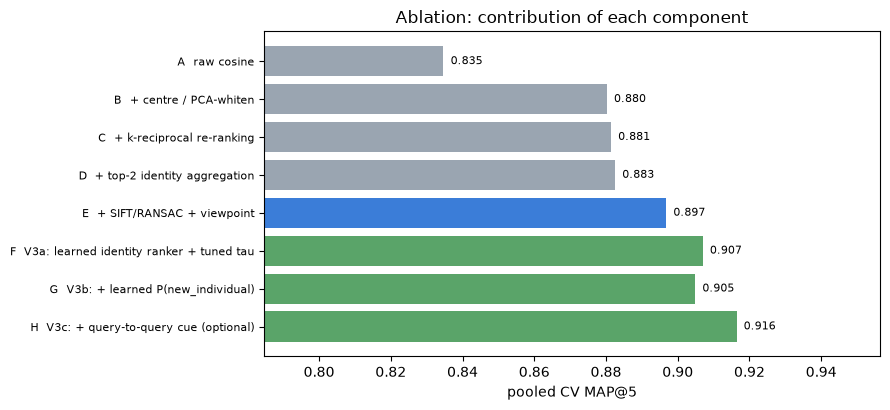

In [35]:
RESULTS_DF = pd.DataFrame(RESULTS).set_index("version")
display_df = RESULTS_DF.round(4)
try: display(display_df)
except NameError: print(display_df.to_string())
RESULTS_DF.to_csv(os.path.join(OUT_DIR, "results_cv.csv"))

fig, ax = plt.subplots(figsize=(9, 4.2))
labels = [v.split("[")[0].strip() for v in RESULTS_DF.index]
ax.barh(range(len(RESULTS_DF)), RESULTS_DF["MAP@5"], color=["#9aa5b1"] * 4 + ["#3b7dd8"] + ["#5aa469"] * 3)
ax.set_yticks(range(len(RESULTS_DF))); ax.set_yticklabels(labels, fontsize=8); ax.invert_yaxis()
for i, v in enumerate(RESULTS_DF["MAP@5"]): ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlabel("pooled CV MAP@5"); ax.set_xlim(RESULTS_DF["MAP@5"].min() - 0.05, RESULTS_DF["MAP@5"].max() + 0.04)
ax.set_title("Ablation: contribution of each component"); savefig("ablation.png")

### Self-check: the vectorised metric equals the plain definition

In [36]:
lists_chk = make_lists(top3, sc3, Q_oof[V3_NEWCOL].to_numpy())
truth_names = np.where(tcode_oof >= 0, CLASSES[np.maximum(tcode_oof, 0)], NEW)
ref = map5([l.split() for l in lists_chk], truth_names)
assert abs(ref - V3_RES["ap"].mean()) < 1e-9, (ref, V3_RES["ap"].mean())
print(f"reference MAP@5 on the written-format lists = {ref:.6f}  (matches the vectorised value)")

reference MAP@5 on the written-format lists = 0.904863  (matches the vectorised value)


## 11. Error analysis of the final model (V3)

                                                        queries   share  MAP lost
known: in candidates but outside top-5 (ranking error)      182  0.0254    0.0254
new: a known identity ranked above NEW (false match)        295  0.0412    0.0215
known: correct @2-5 (ranking error)                         193  0.0269    0.0187
known: right identity first, but NEW placed above it        220  0.0307    0.0154
known: true identity not retrieved (retrieval miss)         102  0.0142    0.0142
new: NEW ranked 1st (correct)                              2589  0.3614    0.0000
known: correct @1                                          3582  0.5001    0.0000

total MAP lost = 0.0951  (1 - MAP@5)


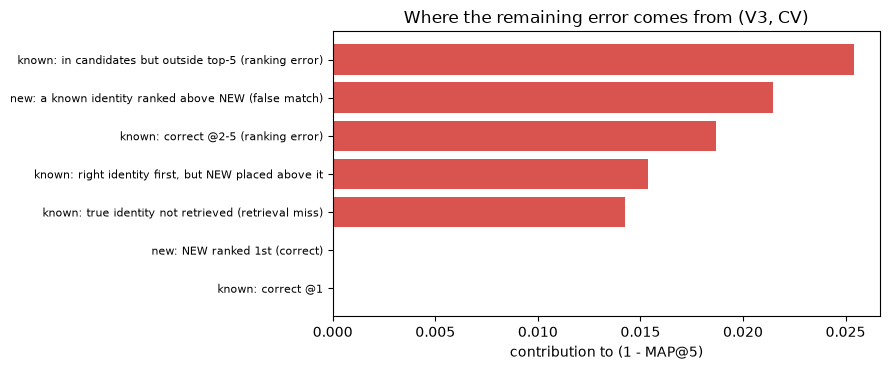

In [37]:
ap, r, pos = V3_RES["ap"], V3_RES["r"], V3_RES["pos"]
new_q = tcode_oof < 0; rank_final = np.where(r >= pos, r + 2, r + 1)
cat = np.empty(len(ap), dtype=object)
cat[new_q & (pos == 0)] = "new: NEW ranked 1st (correct)"
cat[new_q & (pos > 0)]  = "new: a known identity ranked above NEW (false match)"
kn = ~new_q
cat[kn & (rank_final == 1)]                        = "known: correct @1"
cat[kn & (r == 0) & (rank_final == 2)]             = "known: right identity first, but NEW placed above it"
cat[kn & (rank_final >= 2) & (rank_final <= 5) & ~((r == 0) & (rank_final == 2))] = "known: correct @2-5 (ranking error)"
cat[kn & (rank_final > 5) & has_truth]             = "known: in candidates but outside top-5 (ranking error)"
cat[kn & ~has_truth]                               = "known: true identity not retrieved (retrieval miss)"
tax = pd.DataFrame({"queries": pd.Series(cat).value_counts(), "share": pd.Series(cat).value_counts(normalize=True).round(4)})
tax["MAP lost"] = [ (1 - ap[cat == c]).sum() / len(ap) for c in tax.index]
tax = tax.sort_values("MAP lost", ascending=False)
print(tax.round(4).to_string())
print("\ntotal MAP lost = %.4f  (1 - MAP@5)" % (1 - ap.mean()))
fig, ax = plt.subplots(figsize=(9, 3.8)); ax.barh(range(len(tax)), tax["MAP lost"], color="#d9534f")
ax.set_yticks(range(len(tax))); ax.set_yticklabels(tax.index, fontsize=8); ax.invert_yaxis(); ax.set_xlabel("contribution to (1 - MAP@5)")
ax.set_title("Where the remaining error comes from (V3, CV)"); savefig("failure_taxonomy.png")

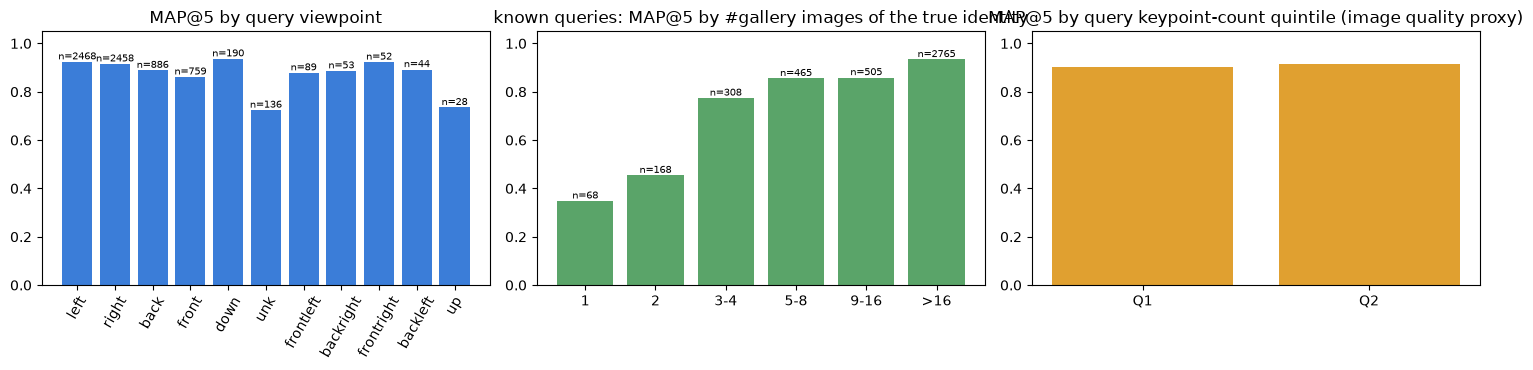

                 mean  size
sp      new                
hyena   False  0.8753  1405
        True   0.9170   507
leopard False  0.8773  2874
        True   0.9530  2377


In [38]:
# ---- slices: viewpoint, identity frequency in the gallery, keypoint count, species x known/new ----
tmp = pd.DataFrame({"ident": tr.identity.to_numpy(dtype=object), "fold": fold_tr}); tot = tmp.groupby("ident").size(); infold = tmp.groupby(["ident", "fold"]).size()
ident_q = tmp.ident.to_numpy()[P_OOF["q_rows"]]
gal_size = tot.reindex(ident_q).to_numpy() - infold.reindex(pd.MultiIndex.from_arrays([ident_q, P_OOF["fold"].astype(np.int64)])).to_numpy()
D_ = pd.DataFrame({"ap": ap, "new": new_q, "vp": np.array(VP_VOCAB)[P_OOF["q_vp"]], "kq0": P_OOF["kq"][:, 0], "gal": gal_size, "sp": np.array(SPECIES)[P_OOF["sp"]]})
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
g = D_.groupby("vp").ap.agg(["mean", "size"]).sort_values("size", ascending=False); axs[0].bar(g.index, g["mean"], color="#3b7dd8"); axs[0].set_title("MAP@5 by query viewpoint"); axs[0].tick_params(axis="x", rotation=60)
for i, (m, n) in enumerate(zip(g["mean"], g["size"])): axs[0].text(i, m + 0.01, f"n={n}", ha="center", fontsize=7)
K_ = D_[~D_.new].copy(); K_["bin"] = pd.cut(K_.gal, [0, 1, 2, 4, 8, 16, 10_000], labels=["1", "2", "3-4", "5-8", "9-16", ">16"])
g2 = K_.groupby("bin", observed=True).ap.agg(["mean", "size"]); axs[1].bar(g2.index.astype(str), g2["mean"], color="#5aa469"); axs[1].set_title("known queries: MAP@5 by #gallery images of the true identity")
for i, (m, n) in enumerate(zip(g2["mean"], g2["size"])): axs[1].text(i, m + 0.01, f"n={n}", ha="center", fontsize=7)
D_["kbin"] = pd.qcut(D_.kq0.replace(0, np.nan), 5, duplicates="drop"); g3 = D_.groupby("kbin", observed=True).ap.mean()
axs[2].bar([f"Q{i+1}" for i in range(len(g3))], g3.values, color="#e0a030"); axs[2].set_title("MAP@5 by query keypoint-count quintile (image quality proxy)")
for a in axs: a.set_ylim(0, 1.05)
savefig("slices.png")
print(D_.groupby(["sp", "new"]).ap.agg(["mean", "size"]).round(4))

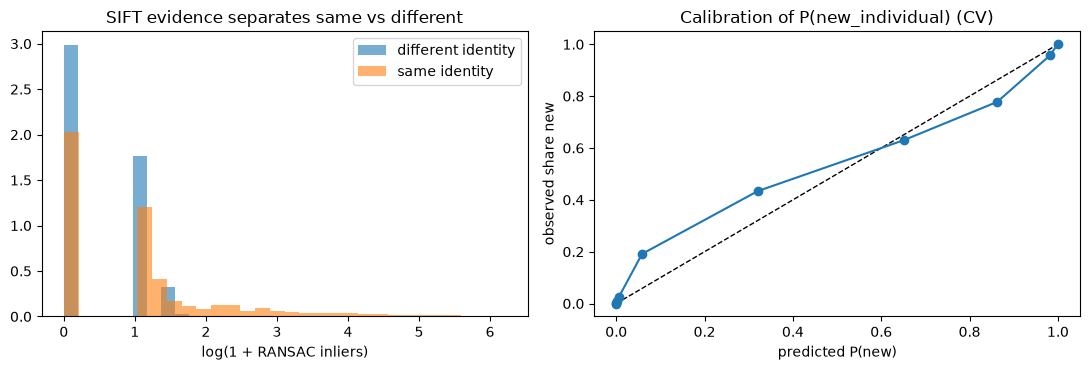

mean predicted P(new) on CV: 0.388 | true new share: 0.403


In [39]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
Mx = min(TOP_M_SIFT, P_OOF["inl"].shape[1]); same_m = (P_OOF["gc"][:, :Mx] == tcode_oof[:, None]) & (tcode_oof[:, None] >= 0)
li = np.log1p(P_OOF["inl"][:, :Mx]); kn_rows = (tcode_oof >= 0)[:, None] & np.ones((1, Mx), bool)
axs[0].hist(li[kn_rows & ~same_m], bins=30, alpha=.6, density=True, label="different identity"); axs[0].hist(li[same_m], bins=30, alpha=.6, density=True, label="same identity")
axs[0].set_xlabel("log(1 + RANSAC inliers)"); axs[0].set_title("SIFT evidence separates same vs different"); axs[0].legend()
pn = Q_oof[V3_NEWCOL].to_numpy(); bins = np.quantile(pn, np.linspace(0, 1, 11)); idx = np.clip(np.digitize(pn, bins[1:-1]), 0, 9)
cal = pd.DataFrame({"pred": pn, "obs": y_new, "b": idx}).groupby("b").mean()
axs[1].plot([0, 1], [0, 1], "k--", lw=1); axs[1].plot(cal.pred, cal.obs, "o-"); axs[1].set_xlabel("predicted P(new)"); axs[1].set_ylabel("observed share new"); axs[1].set_title("Calibration of P(new_individual) (CV)")
savefig("evidence_and_calibration.png")
print("mean predicted P(new) on CV: %.3f | true new share: %.3f" % (pn.mean(), y_new.mean()))

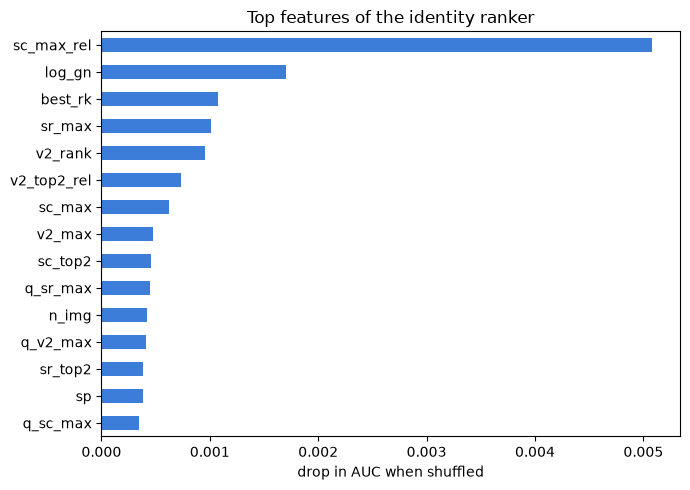

sc_max_rel     0.0051
log_gn         0.0017
best_rk        0.0011
sr_max         0.0010
v2_rank        0.0010
v2_top2_rel    0.0007
sc_max         0.0006
v2_max         0.0005
sc_top2        0.0005
q_sr_max       0.0004


In [40]:
rs = np.random.default_rng(SEED); samp = rs.choice(len(X_id), min(40000, len(X_id)), replace=False)
m_id_tmp = fit_hgb(X_id, T_oof.y.to_numpy())
pi = permutation_importance(m_id_tmp, X_id[samp], T_oof.y.to_numpy()[samp], scoring="roc_auc", n_repeats=3, random_state=SEED)
imp = pd.Series(pi.importances_mean, index=ID_FEATS).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 5)); imp.head(15)[::-1].plot.barh(ax=ax, color="#3b7dd8"); ax.set_xlabel("drop in AUC when shuffled"); ax.set_title("Top features of the identity ranker"); savefig("feature_importance.png")
print(imp.head(10).round(4).to_string())

## 12. Final models, test inference and submission files (one per version)

* **V1**: raw cosine, max aggregation, per-species τ from CV.
* **V2**: V2 blend + top-2 aggregation, per-species τ re-tuned on the new CV.
* **V3**: identity ranker and P(new) models refit on **all** out-of-fold rows, applied to the test pool.

In [41]:
preds_by_version = {}
def to_series(lists, P):
    s = np.empty(len(te), dtype=object); s[P["q_rows"]] = lists; return s

# V1
top, sc = agg_topk(P_TE["r_sc"], P_TE["r_gc"], "max")
preds_by_version["v1"] = to_series(make_lists(top, sc, RES_A["taus"][P_TE["sp"].astype(int)]), P_TE)
# V2
top, sc = agg_topk(blend(P_TE, BEST_PARAMS), P_TE["gc"], BEST_PARAMS["agg"])
preds_by_version["v2"] = to_series(make_lists(top, sc, RES_E["taus"][P_TE["sp"].astype(int)]), P_TE)
# V3
model_id  = fit_model(X_id, T_oof.y.to_numpy())
model_new = fit_model(Q_oof[V3_FEATS].to_numpy(np.float32), y_new)
T_te = identity_table(P_TE); T_te["p"] = model_id.predict_proba(T_te[ID_FEATS].to_numpy(np.float32))[:, 1]
top_te, sc_te = top_from_table(T_te, len(P_TE["sp"]), "p", 5)
Q_te = query_table(P_TE, T_te, len(P_TE["sp"])); pnew_te = model_new.predict_proba(Q_te[V3_FEATS].to_numpy(np.float32))[:, 1]
preds_by_version["v3"] = to_series(make_lists(top_te, sc_te, pnew_te), P_TE)
print("mean predicted P(new) on TEST: %.3f   (CV true new share: %.3f)" % (pnew_te.mean(), y_new.mean()))
print("  by species:", {s: round(float(pnew_te[P_TE['sp'] == i].mean()), 3) for i, s in enumerate(SPECIES)})

mean predicted P(new) on TEST: 0.347   (CV true new share: 0.403)
  by species: {'hyena': 0.346, 'leopard': 0.348}


In [42]:
ss_path = f"{DATA_DIR}/sample_submission.csv"
ss = pd.read_csv(ss_path) if os.path.exists(ss_path) else None
ident_species = tr.drop_duplicates("identity").set_index("identity").species.to_dict(); test_species = te.set_index("id").species.to_dict()

def check_and_write(tag, arr):
    sub = pd.DataFrame({"id": te.id.to_numpy(), "predictions": arr})
    assert not sub.predictions.isna().any(), "NaN predictions"
    if ss is not None: assert len(sub) == len(ss) and set(sub.id) == set(ss.id) and sub.id.is_unique, "ids differ from sample_submission"
    nr = Counter()
    for i, p in zip(sub.id, sub.predictions):
        labs = p.split(); assert 1 <= len(labs) <= 5 and len(set(labs)) == len(labs), f"bad label count/dupes in {i}"
        for l in labs: assert l == NEW or (l in ident_species and ident_species[l] == test_species[i]), f"invalid label {l} for {i}"
        nr[labs.index(NEW) + 1 if NEW in labs else 0] += 1
    path = os.path.join(OUT_DIR, f"submission_{tag}.csv"); sub.to_csv(path, index=False)
    print(f"{tag}: OK -> {path} | new@1 rate {nr[1] / len(sub):.1%} | NEW absent from list: {nr[0]}")
    return sub

subs = {k: check_and_write(k, v) for k, v in preds_by_version.items()}
print(subs["v3"].sample(min(6, len(te)), random_state=0).to_string(index=False))
subs[SUBMIT_VERSION].to_csv(os.path.join(OUT_DIR, "submission.csv"), index=False)
print(f">>> submission.csv written from version {SUBMIT_VERSION.upper()}")

prev = next((p for p in ["submission.csv", os.path.join(DATA_DIR, "submission.csv")] if os.path.isfile(p)), None)    # earlier file, if present
if prev:
    old = pd.read_csv(prev).set_index("id").predictions.str.split().str[0]
    for k, s in subs.items():
        cur = s.set_index("id").predictions.str.split().str[0]; common = old.index.intersection(cur.index)
        print(f"top-1 agreement of {k} with previous {prev}: {(old[common] == cur[common]).mean():.1%}")

v1: OK -> .\submission_v1.csv | new@1 rate 54.5% | NEW absent from list: 0
v2: OK -> .\submission_v2.csv | new@1 rate 41.2% | NEW absent from list: 0
v3: OK -> .\submission_v3.csv | new@1 rate 41.8% | NEW absent from list: 0
      id                                    predictions
te_02465 HYE0236 new_individual HYE0179 HYE0346 HYE0619
te_00689 new_individual LEO0486 LEO0518 LEO0614 LEO0508
te_02684 new_individual HYE0675 HYE0512 HYE0350 HYE0515
te_00992 HYE0524 new_individual HYE0052 HYE0034 HYE0446
te_00617 HYE0188 HYE0125 HYE0490 HYE0222 new_individual
te_00228 new_individual LEO0147 LEO0469 LEO0386 LEO0156
>>> submission.csv written from version V3
top-1 agreement of v1 with previous submission.csv: 79.4%
top-1 agreement of v2 with previous submission.csv: 91.5%
top-1 agreement of v3 with previous submission.csv: 100.0%
